# A/B Test Analysis: Cookie Cats gate placement (gate_30 vs gate_40)
**Question:** Does moving the first gate from level 30 to level 40 change player retention?
**Primary metric:** 7-day retention. **Secondary:** 1-day retention, game rounds played.
Dataset: Kaggle "Mobile Games A/B Testing - Cookie Cats" (cookie_cats.csv)

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.multitest import multipletests

df = pd.read_csv("cookie_cats.csv")   # put the Kaggle file next to this notebook
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Data quality checks

In [2]:
print("Duplicate users:", df.userid.duplicated().sum())
print("Missing values:\n", df.isna().sum())
print(df.sum_gamerounds.describe())

# one extreme outlier distorts averages; inspect and remove
print(df.sort_values("sum_gamerounds", ascending=False).head(3))
df = df[df.sum_gamerounds < df.sum_gamerounds.quantile(0.9999)].copy()

Duplicate users: 0
Missing values:
 userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64
        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False


## 2. Sample Ratio Mismatch (SRM) check
If randomisation worked, the groups should be about 50/50.

In [3]:
counts = df.version.value_counts()
print(counts)
chi2, p = stats.chisquare(counts.values)   # expects equal split
print(f"SRM chi-square p-value = {p:.4f}  (p < 0.01 would signal a broken split)")

version
gate_40    45484
gate_30    44695
Name: count, dtype: int64
SRM chi-square p-value = 0.0086  (p < 0.01 would signal a broken split)


## 3. Metrics by group

In [4]:
summary = df.groupby("version").agg(
    users=("userid", "count"),
    ret1=("retention_1", "mean"),
    ret7=("retention_7", "mean"),
    mean_rounds=("sum_gamerounds", "mean"),
    median_rounds=("sum_gamerounds", "median"),
)
summary

,users,ret1,ret7,mean_rounds,median_rounds
version,,,,,
gate_30,44695,0.448149,0.190111,51.127307,17.0
gate_40,45484,0.442221,0.181932,51.059581,16.0


## 4. Power analysis
How many users per group do we need to detect a 1 percentage-point lift in 7-day retention?

In [5]:
base = df.retention_7.mean()
analysis = NormalIndPower()
for lift in [0.005, 0.01, 0.02]:
    es = proportion_effectsize(base + lift, base)
    n = analysis.solve_power(effect_size=es, alpha=0.05, power=0.8, ratio=1)
    print(f"Detect +{lift*100:.1f}pp (baseline {base:.1%}): need ~{n:,.0f} users per group")

n_actual = counts.min()
es_min = analysis.solve_power(nobs1=n_actual, alpha=0.05, power=0.8, ratio=1)
print(f"\nWith {n_actual:,} users per group we can detect an effect size of {es_min:.3f} (Cohen's h) at 80% power")

Detect +0.5pp (baseline 18.6%): need ~96,040 users per group
Detect +1.0pp (baseline 18.6%): need ~24,251 users per group
Detect +2.0pp (baseline 18.6%): need ~6,180 users per group

With 44,695 users per group we can detect an effect size of 0.019 (Cohen's h) at 80% power


## 5. Significance tests and confidence intervals (retention)

In [6]:
a = df[df.version == "gate_30"]; b = df[df.version == "gate_40"]
results = []
for metric in ["retention_1", "retention_7"]:
    x = np.array([a[metric].sum(), b[metric].sum()])
    n = np.array([len(a), len(b)])
    z, p = proportions_ztest(x, n)
    lo, hi = confint_proportions_2indep(x[1], n[1], x[0], n[0], compare="diff")
    results.append(dict(metric=metric, gate_30=x[0]/n[0], gate_40=x[1]/n[1],
                        diff=x[1]/n[1]-x[0]/n[0], ci_low=lo, ci_high=hi, p_value=p))
res = pd.DataFrame(results)

# correct for testing two metrics
res["p_adj_holm"] = multipletests(res.p_value, method="holm")[1]
res

,metric,gate_30,gate_40,diff,ci_low,ci_high,p_value,p_adj_holm
0,retention_1,0.448149,0.442221,-0.005927,-0.012414,0.000560,0.073351,0.073351
1,retention_7,0.190111,0.181932,-0.008179,-0.013259,-0.003099,0.001600,0.003199


## 6. Bootstrap CI for 7-day retention (no distribution assumptions)

Bootstrap 95% CI for diff (gate_40 - gate_30): [-0.0131, -0.0034]


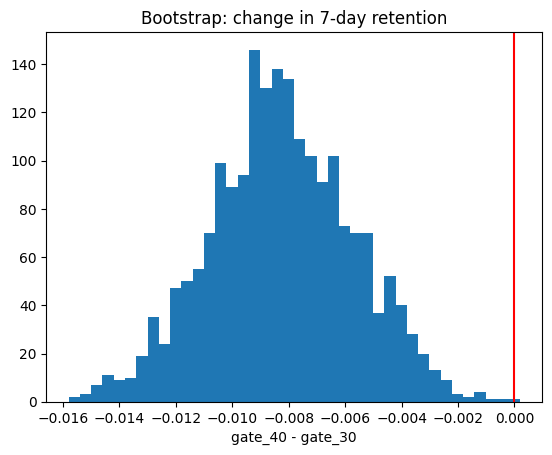

In [7]:
rng = np.random.default_rng(42)
boot = []
for _ in range(2000):
    sa = rng.choice(a.retention_7.values, len(a)); sb = rng.choice(b.retention_7.values, len(b))
    boot.append(sb.mean() - sa.mean())
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Bootstrap 95% CI for diff (gate_40 - gate_30): [{lo:.4f}, {hi:.4f}]")
plt.hist(boot, bins=40); plt.axvline(0, color="red"); plt.title("Bootstrap: change in 7-day retention")
plt.xlabel("gate_40 - gate_30"); plt.show()

## 7. Engagement (game rounds): skewed data, so use a non-parametric test

In [8]:
u, p = stats.mannwhitneyu(a.sum_gamerounds, b.sum_gamerounds, alternative="two-sided")
print(f"Mann-Whitney U p-value = {p:.4f}")
print(df.groupby("version").sum_gamerounds.median())

Mann-Whitney U p-value = 0.0502
version
gate_30    17.0
gate_40    16.0
Name: sum_gamerounds, dtype: float64


## 8. Bayesian view: probability that gate_30 is better for 7-day retention

In [9]:
pa = rng.beta(1 + a.retention_7.sum(), 1 + (len(a) - a.retention_7.sum()), 100000)
pb = rng.beta(1 + b.retention_7.sum(), 1 + (len(b) - b.retention_7.sum()), 100000)
print(f"P(gate_30 better than gate_40) = {(pa > pb).mean():.1%}")

P(gate_30 better than gate_40) = 99.9%


## 9. Business recommendation

- **Result:** 7-day retention was 19.02% (gate_30) vs 18.20% (gate_40), a difference of -0.82 percentage points (95% CI about -1.33 to -0.31), statistically significant after multiple-testing correction. 1-day retention also fell (-0.59 pp) but was not significant.
- **Interpretation:** the drop is small per player but real, and the Bayesian check gives a 99.9% probability that gate_30 is better for 7-day retention. Engagement (rounds played) is essentially unchanged (Mann-Whitney p = 0.050, borderline), so gate_40 has no upside.
- **Decision:** keep the gate at level 30.
- **Caveats:** the groups are slightly uneven (SRM p-value about 0.009), only retention and rounds were measured (no revenue), and this covers a single test period.
- **Next step:** test a revenue metric or an intermediate gate (level 35).